In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# ============================================================
# Brain Tumor MRI Dataset - 3 Modern Models in One Cell
# Dataset: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
# Models:
#   1) Vision Transformer (ViT) - custom, fine-tuned
#   2) Xception (Transfer Learning)
#   3) Improved EfficientNetB0 (Custom EfficientNet variant)
# EPOCHS = 100 (with EarlyStopping)
# ============================================================

# ----------------- Basic libs & data path detection -----------------
import numpy as np
import pandas as pd
import os

print("Listing /kaggle/input contents:")
for dirname, _, _ in os.walk('/kaggle/input'):
    print(dirname)

# Auto-detect dataset folder under /kaggle/input
data_path = None
for dirname, _, _ in os.walk('/kaggle/input'):
    if 'brain-tumor-mri-dataset' in dirname:
        data_path = dirname
        break

if data_path is None:
    raise FileNotFoundError("Could not find 'brain-tumor-mri-dataset' under /kaggle/input")

print(f"\nUsing data_path: {data_path}")

train_dir = os.path.join(data_path, "Training")
test_dir  = os.path.join(data_path, "Testing")
print("Train dir:", train_dir)
print("Test dir :", test_dir)

# ----------------- TensorFlow & Keras imports -----------------
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import Xception, EfficientNetB0

print("TensorFlow version:", tf.__version__)

# ----------------- Global config -----------------
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
SEED       = 42
EPOCHS     = 100   # as requested

# ============================================================
# DATA PIPELINE (TRAIN / VALIDATION / TEST)
# ============================================================
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2,
)

test_datagen = ImageDataGenerator(rescale=1.0/255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED
)

val_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

class_indices = train_gen.class_indices
num_classes = len(class_indices)
print("Classes:", class_indices)

# ============================================================
# HELPER: TRANSFORMER ENCODER BLOCK (for ViT)
# ============================================================
def transformer_encoder(inputs, num_heads, mlp_dim, dropout=0.1):
    # Layer norm 1 + Multi-head Self-Attention
    x = layers.LayerNormalization(epsilon=1e-6)(inputs)
    x = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=inputs.shape[-1],
        dropout=dropout
    )(x, x)
    x = layers.Dropout(dropout)(x)
    x = layers.Add()([x, inputs])  # residual 1

    # Layer norm 2 + MLP
    y = layers.LayerNormalization(epsilon=1e-6)(x)
    y = layers.Dense(mlp_dim, activation="gelu")(y)
    y = layers.Dropout(dropout)(y)
    y = layers.Dense(inputs.shape[-1])(y)
    y = layers.Dropout(dropout)(y)

    # Residual 2
    return layers.Add()([x, y])

# ============================================================
# MODEL 1: Vision Transformer (ViT) - Custom Implementation (FIXED)
# ============================================================
def build_vit_model(
    image_size=224,
    patch_size=16,
    num_layers=8,
    d_model=256,
    num_heads=8,
    mlp_dim=512,
    dropout=0.1,
    num_classes=4,
):
    """
    ViT-style model without explicit class token:
    - Patch embedding via Conv2D
    - Positional embeddings via Embedding
    - Stacked Transformer encoder blocks
    - GlobalAveragePooling over tokens for classification
    """

    # Input
    inputs = keras.Input(shape=(image_size, image_size, 3))

    # Patch embedding: Conv2D with stride=patch_size
    # (H, W, C) -> (H/patch, W/patch, d_model)
    x = layers.Conv2D(
        filters=d_model,
        kernel_size=patch_size,
        strides=patch_size,
        padding="valid",
        name="patch_embedding"
    )(inputs)

    # Flatten spatial dims: (batch, H_p, W_p, d_model) -> (batch, N_patches, d_model)
    patch_dims = (image_size // patch_size) ** 2
    x = layers.Reshape((patch_dims, d_model))(x)  # (batch, N, d_model)

    # Positional embeddings
    positions = tf.range(start=0, limit=patch_dims, delta=1)  # (N,)
    pos_embed_layer = layers.Embedding(
        input_dim=patch_dims,
        output_dim=d_model,
        name="positional_embedding"
    )
    pos_embeddings = pos_embed_layer(positions)  # (N, d_model)

    # Broadcasting: (batch, N, d_model) + (N, d_model) -> (batch, N, d_model)
    x = x + pos_embeddings

    # Transformer encoder blocks
    for _ in range(num_layers):
        x = transformer_encoder(
            x,
            num_heads=num_heads,
            mlp_dim=mlp_dim,
            dropout=dropout
        )

    # Final norm + pooling over tokens
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.GlobalAveragePooling1D()(x)  # (batch, d_model)

    # Classification head
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="ViT_brain_tumor")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ============================================================
# MODEL 2: Xception (Transfer Learning)
# ============================================================
def build_xception_model(num_classes=4, img_size=(224, 224)):
    base_model = Xception(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,)
    )
    base_model.trainable = False  # frozen feature extractor

    inputs = keras.Input(shape=img_size + (3,))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="Xception_brain_tumor")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ============================================================
# MODEL 3: Improved EfficientNetB0 (Custom Variant)
# ============================================================
def build_improved_efficientnet(num_classes=4, img_size=(224, 224)):
    """
    'Improved' EfficientNet idea:
    - EfficientNetB0 backbone (pretrained)
    - Deeper custom classification head with Dropout & BN
    """
    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,)
    )
    base_model.trainable = False  # start frozen

    inputs = keras.Input(shape=img_size + (3,))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)

    # Custom "improved" head
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="Improved_EfficientNetB0")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ============================================================
# TRAINING LOOP FOR ALL THREE MODELS
# ============================================================
callbacks_common = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

models_builders = {
    "ViT": lambda: build_vit_model(
        image_size=IMG_SIZE[0],
        patch_size=16,
        num_layers=8,
        d_model=256,
        num_heads=8,
        mlp_dim=512,
        dropout=0.1,
        num_classes=num_classes
    ),
    "Xception": lambda: build_xception_model(
        num_classes=num_classes,
        img_size=IMG_SIZE
    ),
    "Improved_EfficientNet": lambda: build_improved_efficientnet(
        num_classes=num_classes,
        img_size=IMG_SIZE
    )
}

histories = {}
results   = {}

for name, builder in models_builders.items():
    print("\n" + "="*70)
    print(f"Training model: {name}")
    print("="*70)

    tf.keras.backend.clear_session()
    model = builder()
    model.summary()

    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS,
        callbacks=callbacks_common,
        verbose=1
    )
    histories[name] = history.history

    print(f"\nEvaluating {name} on TEST set...")
    test_loss, test_acc = model.evaluate(test_gen, verbose=1)
    results[name] = {"test_loss": test_loss, "test_acc": test_acc}
    print(f"{name} - Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")

# ============================================================
# FINAL COMPARISON
# ============================================================
print("\n\n================ FINAL TEST RESULTS ================")
for name, res in results.items():
    print(f"{name:22s} -> Acc: {res['test_acc']:.4f} | Loss: {res['test_loss']:.4f}")
print("====================================================")


Listing /kaggle/input contents:
/kaggle/input
/kaggle/input/brain-tumor-mri-dataset
/kaggle/input/brain-tumor-mri-dataset/Training
/kaggle/input/brain-tumor-mri-dataset/Training/pituitary
/kaggle/input/brain-tumor-mri-dataset/Training/notumor
/kaggle/input/brain-tumor-mri-dataset/Training/meningioma
/kaggle/input/brain-tumor-mri-dataset/Training/glioma
/kaggle/input/brain-tumor-mri-dataset/Testing
/kaggle/input/brain-tumor-mri-dataset/Testing/pituitary
/kaggle/input/brain-tumor-mri-dataset/Testing/notumor
/kaggle/input/brain-tumor-mri-dataset/Testing/meningioma
/kaggle/input/brain-tumor-mri-dataset/Testing/glioma

Using data_path: /kaggle/input/brain-tumor-mri-dataset
Train dir: /kaggle/input/brain-tumor-mri-dataset/Training
Test dir : /kaggle/input/brain-tumor-mri-dataset/Testing
TensorFlow version: 2.18.0
Found 4571 images belonging to 4 classes.
Found 1141 images belonging to 4 classes.
Found 1311 images belonging to 4 classes.
Classes: {'glioma': 0, 'meningioma': 1, 'notumor': 2, '

Model: "ViT_brain_tumor"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 14, 14,    │    196,864 │ input_layer[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 256)  │          0 │ patch_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 256)  │          0 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 256)  │        512 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 256)  │  2,103,552 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 196, 256)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 256)  │          0 │ dropout_1[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 256)  │        512 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 196, 512)  │    131,584 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 196, 512)  │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 196, 256)  │    131,328 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 196, 256)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 256)  │          0 │ add_1[0][0],      │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 256)  │        512 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 256)  │  2,103,552 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 196, 256)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 196, 256)  │          0 │ dropout_5[0][0],  │
│                     │                   │            │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 256)  │        512 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 19,138,308 (73.01 MB)

 Trainable params: 19,138,308 (73.01 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,842,919 (18.47 MB)

 Trainable params: 790,788 (3.02 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

Epoch 1/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 107s 592ms/step - accuracy: 0.2694 - loss: 1.4926 - val_accuracy: 0.2550 - val_loss: 1.3887 - learning_rate: 1.0000e-04
Epoch 2/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 63s 441ms/step - accuracy: 0.3206 - loss: 1.3898 - val_accuracy: 0.2463 - val_loss: 1.3827 - learning_rate: 1.0000e-04
Epoch 3/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 64s 447ms/step - accuracy: 0.3474 - loss: 1.3584 - val_accuracy: 0.3611 - val_loss: 1.3738 - learning_rate: 1.0000e-04
Epoch 4/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 64s 448ms/step - accuracy: 0.3708 - loss: 1.3119 - val_accuracy: 0.2840 - val_loss: 1.3670 - learning_rate: 1.0000e-04
Epoch 5/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 65s 453ms/step - accuracy: 0.3641 - loss: 1.2933 - val_accuracy: 0.3602 - val_loss: 1.3602 - learning_rate: 1.0000e-04
Epoch 6/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 64s 450ms/step - accuracy: 0.3703 - loss: 1.2818 - val_accuracy: 0.3103 - val_loss: 1.3519 - learning_rate: 1.0000e-04
Epoch 7/100
143/143 ━━━━━━━━━━━━━━━━━━━

Listing /kaggle/input contents:
/kaggle/input
/kaggle/input/brain-tumor-mri-dataset
/kaggle/input/brain-tumor-mri-dataset/Training
/kaggle/input/brain-tumor-mri-dataset/Training/pituitary
/kaggle/input/brain-tumor-mri-dataset/Training/notumor
/kaggle/input/brain-tumor-mri-dataset/Training/meningioma
/kaggle/input/brain-tumor-mri-dataset/Training/glioma
/kaggle/input/brain-tumor-mri-dataset/Testing
/kaggle/input/brain-tumor-mri-dataset/Testing/pituitary
/kaggle/input/brain-tumor-mri-dataset/Testing/notumor
/kaggle/input/brain-tumor-mri-dataset/Testing/meningioma
/kaggle/input/brain-tumor-mri-dataset/Testing/glioma

Using data_path: /kaggle/input/brain-tumor-mri-dataset
Train dir: /kaggle/input/brain-tumor-mri-dataset/Training
Test dir : /kaggle/input/brain-tumor-mri-dataset/Testing
TensorFlow version: 2.18.0
Found 4571 images belonging to 4 classes.
Found 1141 images belonging to 4 classes.
Found 1311 images belonging to 4 classes.
Found 4571 images belonging to 4 classes.
Found 1141 im

Model: "ViT_brain_tumor"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 14, 14,    │    196,864 │ input_layer[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 256)  │          0 │ patch_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 256)  │          0 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 256)  │        512 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 256)  │  2,103,552 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 196, 256)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 256)  │          0 │ dropout_1[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 256)  │        512 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 196, 512)  │    131,584 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 196, 512)  │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 196, 256)  │    131,328 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 196, 256)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 256)  │          0 │ add_1[0][0],      │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 256)  │        512 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 256)  │  2,103,552 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 196, 256)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 196, 256)  │          0 │ dropout_5[0][0],  │
│                     │                   │            │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 256)  │        512 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 19,138,308 (73.01 MB)

 Trainable params: 19,138,308 (73.01 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,384,679 (16.73 MB)

 Trainable params: 332,036 (1.27 MB)

 Non-trainable params: 4,052,643 (15.46 MB)

Epoch 1/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 102s 575ms/step - accuracy: 0.5839 - loss: 1.1153 - val_accuracy: 0.6380 - val_loss: 0.9541 - learning_rate: 1.0000e-04
Epoch 2/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 63s 442ms/step - accuracy: 0.7848 - loss: 0.6181 - val_accuracy: 0.7038 - val_loss: 0.8235 - learning_rate: 1.0000e-04
Epoch 3/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 63s 442ms/step - accuracy: 0.8156 - loss: 0.4930 - val_accuracy: 0.7362 - val_loss: 0.7250 - learning_rate: 1.0000e-04
Epoch 4/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 64s 449ms/step - accuracy: 0.8475 - loss: 0.4228 - val_accuracy: 0.7783 - val_loss: 0.6586 - learning_rate: 1.0000e-04
Epoch 5/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 63s 443ms/step - accuracy: 0.8478 - loss: 0.4148 - val_accuracy: 0.7862 - val_loss: 0.5873 - learning_rate: 1.0000e-04
Epoch 6/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 63s 442ms/step - accuracy: 0.8589 - loss: 0.4004 - val_accuracy: 0.7949 - val_loss: 0.5937 - learning_rate: 1.0000e-04
Epoch 7/50
143/143 ━━━━━━━━━━━━━━━━━━━━ 65s 4

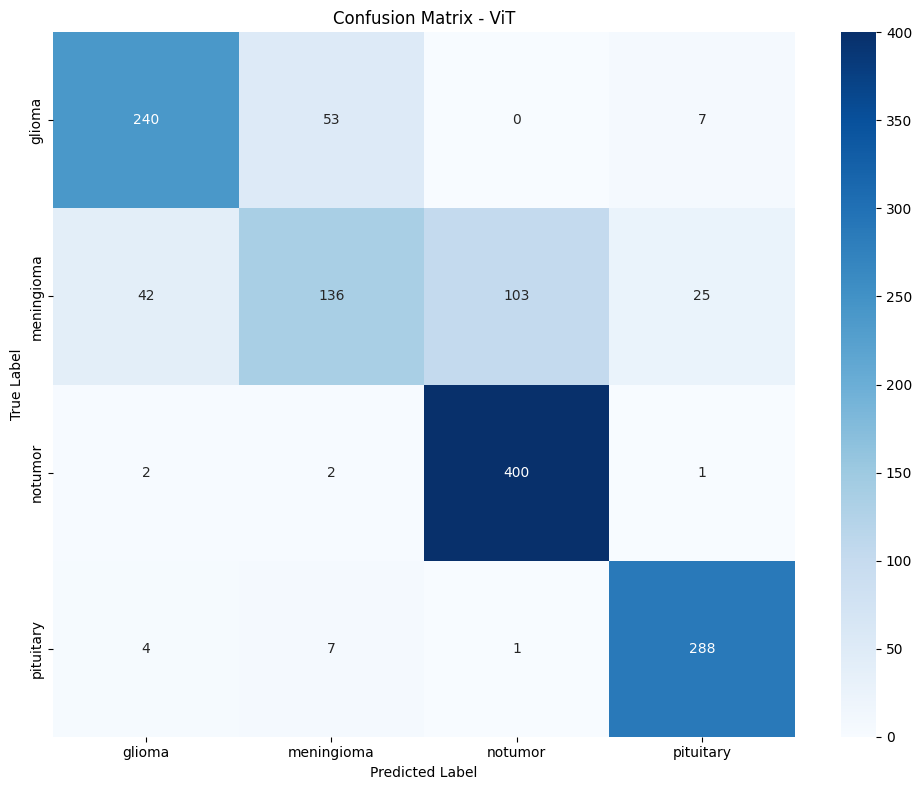

Classification Report - ViT
              precision    recall  f1-score   support

      glioma       0.83      0.80      0.82       300
  meningioma       0.69      0.44      0.54       306
     notumor       0.79      0.99      0.88       405
   pituitary       0.90      0.96      0.93       300

    accuracy                           0.81      1311
   macro avg       0.80      0.80      0.79      1311
weighted avg       0.80      0.81      0.80      1311



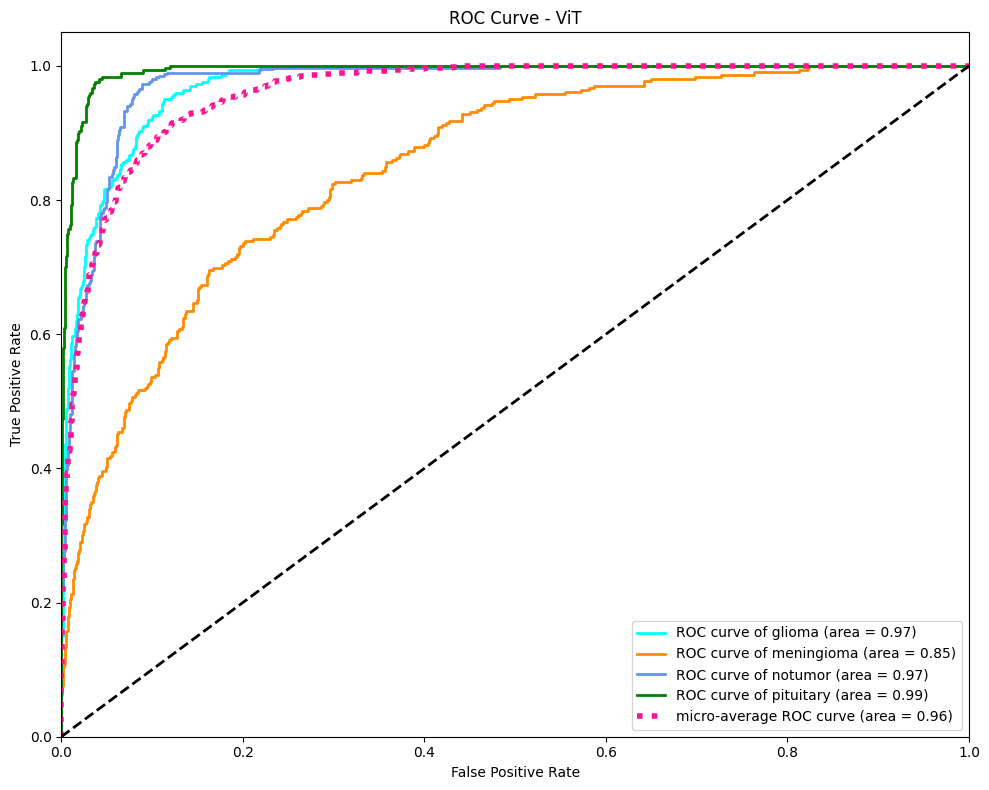

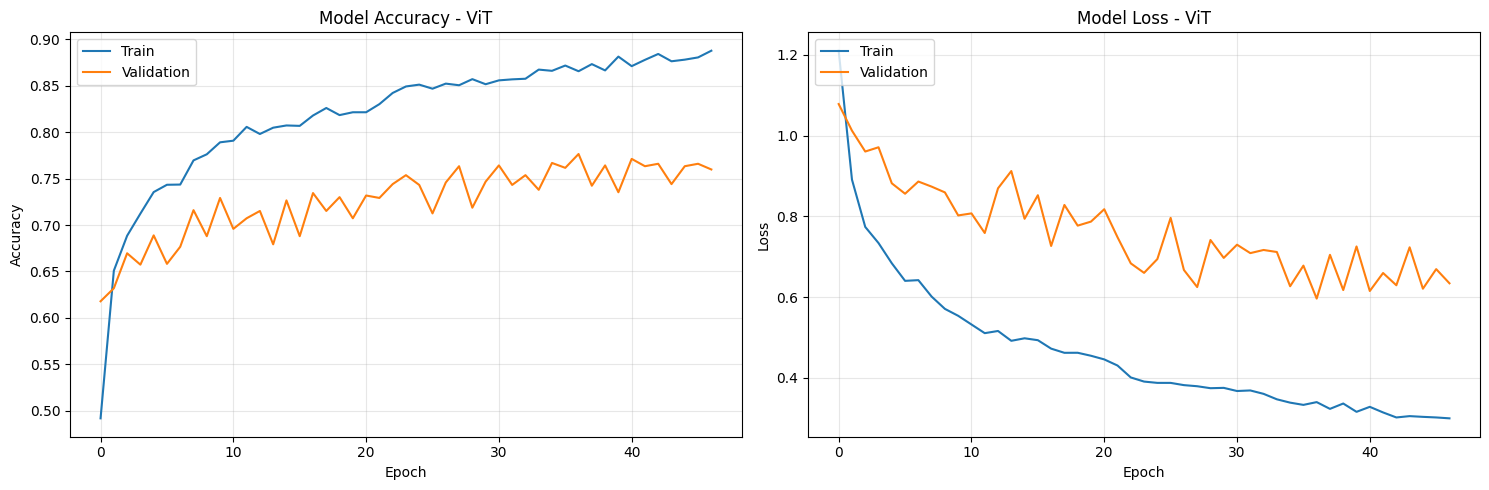


Generating visualizations for Xception


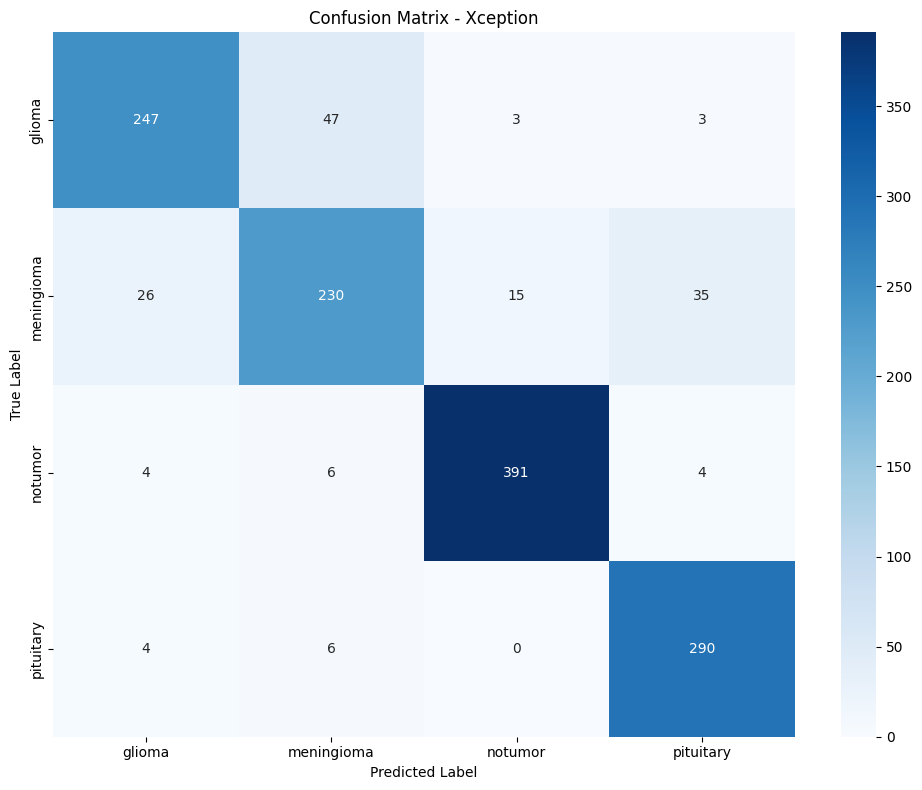

Classification Report - Xception
              precision    recall  f1-score   support

      glioma       0.88      0.82      0.85       300
  meningioma       0.80      0.75      0.77       306
     notumor       0.96      0.97      0.96       405
   pituitary       0.87      0.97      0.92       300

    accuracy                           0.88      1311
   macro avg       0.88      0.88      0.88      1311
weighted avg       0.88      0.88      0.88      1311



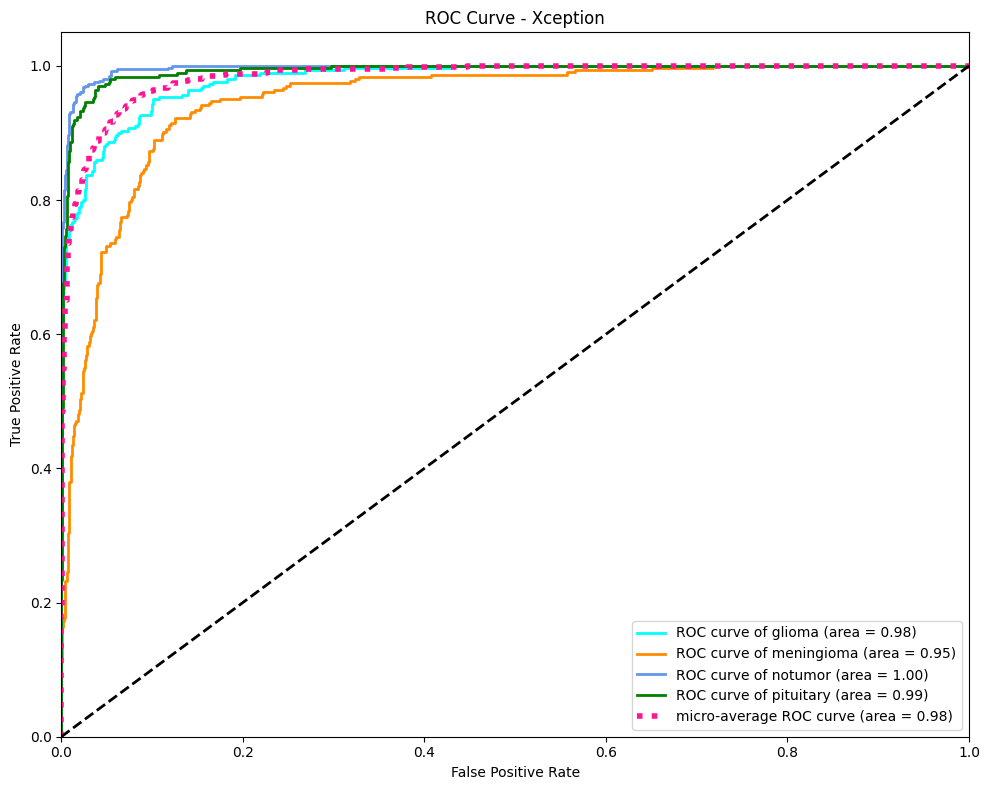

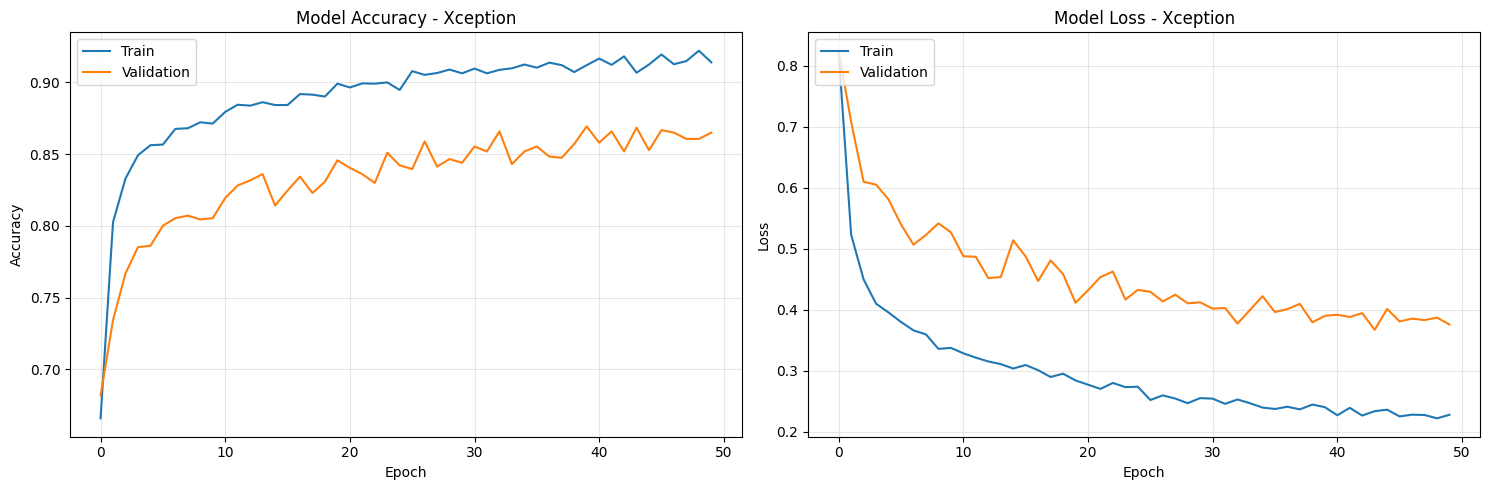


Generating visualizations for EfficientNetB0


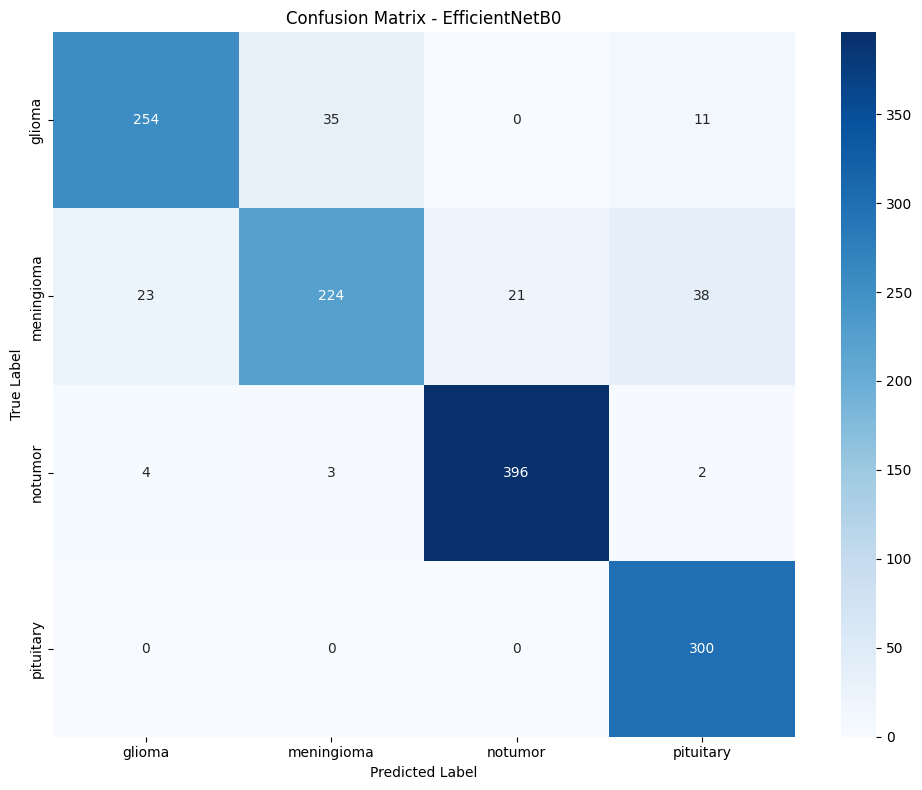

Classification Report - EfficientNetB0
              precision    recall  f1-score   support

      glioma       0.90      0.85      0.87       300
  meningioma       0.85      0.73      0.79       306
     notumor       0.95      0.98      0.96       405
   pituitary       0.85      1.00      0.92       300

    accuracy                           0.90      1311
   macro avg       0.89      0.89      0.89      1311
weighted avg       0.90      0.90      0.89      1311



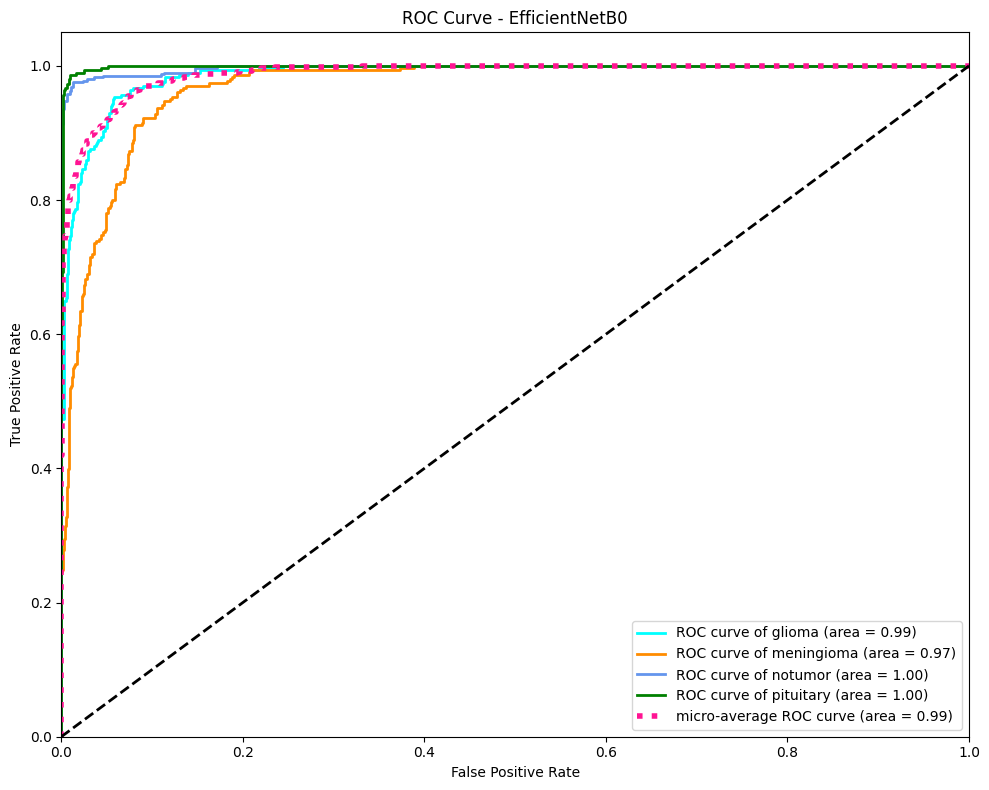

AttributeError: 'dict' object has no attribute 'history'

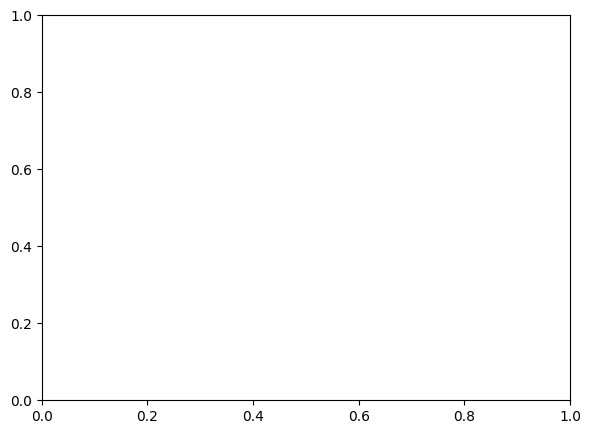

In [3]:
# ============================================================
# Brain Tumor MRI Dataset - 3 Modern Models with Full Visualizations
# Dataset: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
# Models:
#   1) Vision Transformer (ViT) - custom, fine-tuned
#   2) Xception (Transfer Learning)
#   3) Fixed EfficientNetB0 (Transfer Learning with proper head)
# EPOCHS = 100 (with EarlyStopping)
# ============================================================

# ----------------- Basic libs & data path detection -----------------
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

print("Listing /kaggle/input contents:")
for dirname, _, _ in os.walk('/kaggle/input'):
    print(dirname)

# Auto-detect dataset folder under /kaggle/input
data_path = None
for dirname, _, _ in os.walk('/kaggle/input'):
    if 'brain-tumor-mri-dataset' in dirname:
        data_path = dirname
        break

if data_path is None:
    raise FileNotFoundError("Could not find 'brain-tumor-mri-dataset' under /kaggle/input")

print(f"\nUsing data_path: {data_path}")

train_dir = os.path.join(data_path, "Training")
test_dir  = os.path.join(data_path, "Testing")
print("Train dir:", train_dir)
print("Test dir :", test_dir)

# ----------------- TensorFlow & Keras imports -----------------
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import Xception, EfficientNetB0
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

print("TensorFlow version:", tf.__version__)

# ----------------- Global config -----------------
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
SEED       = 42
EPOCHS     = 100   # as requested

# ============================================================
# DATA PIPELINE (TRAIN / VALIDATION / TEST)
# ============================================================
# Create separate data generators for each model with appropriate preprocessing
train_datagen_base = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2,
)

test_datagen_base = ImageDataGenerator()

# Data generator for ViT (no specific preprocessing)
train_gen_vit = train_datagen_base.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED
)

val_gen_vit = train_datagen_base.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=SEED
)

test_gen_vit = test_datagen_base.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Data generator for Xception
train_datagen_xception = ImageDataGenerator(
    preprocessing_function=xception_preprocess,
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2,
)

test_datagen_xception = ImageDataGenerator(preprocessing_function=xception_preprocess)

train_gen_xception = train_datagen_xception.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED
)

val_gen_xception = train_datagen_xception.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=SEED
)

test_gen_xception = test_datagen_xception.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Data generator for EfficientNet
train_datagen_efficientnet = ImageDataGenerator(
    preprocessing_function=efficientnet_preprocess,
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2,
)

test_datagen_efficientnet = ImageDataGenerator(preprocessing_function=efficientnet_preprocess)

train_gen_efficientnet = train_datagen_efficientnet.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED
)

val_gen_efficientnet = train_datagen_efficientnet.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=SEED
)

test_gen_efficientnet = test_datagen_efficientnet.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

class_indices = train_gen_vit.class_indices
num_classes = len(class_indices)
print("Classes:", class_indices)

# ============================================================
# VISUALIZATION FUNCTIONS
# ============================================================
def plot_confusion_matrix(model, test_generator, model_name):
    # Reset the generator and get predictions
    test_generator.reset()
    y_pred = model.predict(test_generator, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    
    # Get true labels
    y_true = test_generator.classes
    class_names = list(test_generator.class_indices.keys())
    
    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred_classes)
    
    # Plot confusion matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{model_name}.png')
    plt.show()
    
    # Print classification report
    print(f"Classification Report - {model_name}")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))
    
    return cm

def plot_roc_curve(model, test_generator, model_name):
    # Reset the generator and get predictions
    test_generator.reset()
    y_pred = model.predict(test_generator, verbose=0)
    
    # Get true labels
    y_true = test_generator.classes
    
    # Binarize the labels for one-vs-rest ROC
    y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))
    
    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    
    for i in range(num_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    
    # Plot ROC curves
    plt.figure(figsize=(10, 8))
    colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green'])
    
    for i, color in zip(range(num_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'ROC curve of {list(test_generator.class_indices.keys())[i]} (area = {roc_auc[i]:.2f})')
    
    plt.plot(fpr["micro"], tpr["micro"], color='deeppink', linestyle=':', linewidth=4,
             label=f'micro-average ROC curve (area = {roc_auc["micro"]:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(f'roc_curve_{model_name}.png')
    plt.show()
    
    return roc_auc

def plot_training_history(history, model_name):
    # Plot training & validation accuracy values
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'Model Accuracy - {model_name}')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid(True, alpha=0.3)
    
    # Plot training & validation loss values
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'Model Loss - {model_name}')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'training_history_{model_name}.png')
    plt.show()

# ============================================================
# HELPER: TRANSFORMER ENCODER BLOCK (for ViT)
# ============================================================
def transformer_encoder(inputs, num_heads, mlp_dim, dropout=0.1):
    # Layer norm 1 + Multi-head Self-Attention
    x = layers.LayerNormalization(epsilon=1e-6)(inputs)
    x = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=inputs.shape[-1],
        dropout=dropout
    )(x, x)
    x = layers.Dropout(dropout)(x)
    x = layers.Add()([x, inputs])  # residual 1

    # Layer norm 2 + MLP
    y = layers.LayerNormalization(epsilon=1e-6)(x)
    y = layers.Dense(mlp_dim, activation="gelu")(y)
    y = layers.Dropout(dropout)(y)
    y = layers.Dense(inputs.shape[-1])(y)
    y = layers.Dropout(dropout)(y)

    # Residual 2
    return layers.Add()([x, y])

# ============================================================
# MODEL 1: Vision Transformer (ViT) - Custom Implementation
# ============================================================
def build_vit_model(
    image_size=224,
    patch_size=16,
    num_layers=8,
    d_model=256,
    num_heads=8,
    mlp_dim=512,
    dropout=0.1,
    num_classes=4,
):
    """
    ViT-style model without explicit class token:
    - Patch embedding via Conv2D
    - Positional embeddings via Embedding
    - Stacked Transformer encoder blocks
    - GlobalAveragePooling over tokens for classification
    """

    # Input
    inputs = keras.Input(shape=(image_size, image_size, 3))

    # Patch embedding: Conv2D with stride=patch_size
    # (H, W, C) -> (H/patch, W/patch, d_model)
    x = layers.Conv2D(
        filters=d_model,
        kernel_size=patch_size,
        strides=patch_size,
        padding="valid",
        name="patch_embedding"
    )(inputs)

    # Flatten spatial dims: (batch, H_p, W_p, d_model) -> (batch, N_patches, d_model)
    patch_dims = (image_size // patch_size) ** 2
    x = layers.Reshape((patch_dims, d_model))(x)  # (batch, N, d_model)

    # Positional embeddings
    positions = tf.range(start=0, limit=patch_dims, delta=1)  # (N,)
    pos_embed_layer = layers.Embedding(
        input_dim=patch_dims,
        output_dim=d_model,
        name="positional_embedding"
    )
    pos_embeddings = pos_embed_layer(positions)  # (N, d_model)

    # Broadcasting: (batch, N, d_model) + (N, d_model) -> (batch, N, d_model)
    x = x + pos_embeddings

    # Transformer encoder blocks
    for _ in range(num_layers):
        x = transformer_encoder(
            x,
            num_heads=num_heads,
            mlp_dim=mlp_dim,
            dropout=dropout
        )

    # Final norm + pooling over tokens
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.GlobalAveragePooling1D()(x)  # (batch, d_model)

    # Classification head
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="ViT_brain_tumor")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ============================================================
# MODEL 2: Xception (Transfer Learning)
# ============================================================
def build_xception_model(num_classes=4, img_size=(224, 224)):
    base_model = Xception(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,)
    )
    base_model.trainable = False  # frozen feature extractor

    inputs = keras.Input(shape=img_size + (3,))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="Xception_brain_tumor")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ============================================================
# MODEL 3: Fixed EfficientNetB0 (Transfer Learning)
# ============================================================
def build_efficientnet_model(num_classes=4, img_size=(224, 224)):
    """
    Fixed EfficientNet with proper transfer learning approach:
    - EfficientNetB0 backbone (pretrained)
    - Proper classification head with appropriate layers
    - Fine-tuning after initial training
    """
    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,)
    )
    base_model.trainable = False  # Start with frozen backbone

    inputs = keras.Input(shape=img_size + (3,))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    
    # Proper classification head
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="EfficientNetB0_brain_tumor")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

# Function to fine-tune EfficientNet
def fine_tune_efficientnet(model, base_model):
    # Unfreeze the top layers of the model
    base_model.trainable = True
    
    # Let's unfreeze the top 20 layers
    for layer in base_model.layers[:-20]:
        layer.trainable = False
    
    # Re-compile the model with a very low learning rate
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

# ============================================================
# TRAINING LOOP FOR ALL THREE MODELS
# ============================================================
callbacks_common = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

# Model 1: ViT
print("\n" + "="*70)
print("Training model: ViT")
print("="*70)

tf.keras.backend.clear_session()
model_vit = build_vit_model(
    image_size=IMG_SIZE[0],
    patch_size=16,
    num_layers=8,
    d_model=256,
    num_heads=8,
    mlp_dim=512,
    dropout=0.1,
    num_classes=num_classes
)
model_vit.summary()

history_vit = model_vit.fit(
    train_gen_vit,
    validation_data=val_gen_vit,
    epochs=EPOCHS,
    callbacks=callbacks_common,
    verbose=1
)

print(f"\nEvaluating ViT on TEST set...")
test_loss_vit, test_acc_vit = model_vit.evaluate(test_gen_vit, verbose=1)
print(f"ViT - Test Accuracy: {test_acc_vit:.4f} | Test Loss: {test_loss_vit:.4f}")

# Model 2: Xception
print("\n" + "="*70)
print("Training model: Xception")
print("="*70)

tf.keras.backend.clear_session()
model_xception = build_xception_model(
    num_classes=num_classes,
    img_size=IMG_SIZE
)
model_xception.summary()

history_xception = model_xception.fit(
    train_gen_xception,
    validation_data=val_gen_xception,
    epochs=EPOCHS,
    callbacks=callbacks_common,
    verbose=1
)

print(f"\nEvaluating Xception on TEST set...")
test_loss_xception, test_acc_xception = model_xception.evaluate(test_gen_xception, verbose=1)
print(f"Xception - Test Accuracy: {test_acc_xception:.4f} | Test Loss: {test_loss_xception:.4f}")

# Model 3: EfficientNet
print("\n" + "="*70)
print("Training model: EfficientNetB0")
print("="*70)

tf.keras.backend.clear_session()
model_efficientnet, base_model_efficientnet = build_efficientnet_model(
    num_classes=num_classes,
    img_size=IMG_SIZE
)
model_efficientnet.summary()

# Initial training with frozen backbone
history_efficientnet = model_efficientnet.fit(
    train_gen_efficientnet,
    validation_data=val_gen_efficientnet,
    epochs=50,  # Initial training with frozen backbone
    callbacks=callbacks_common,
    verbose=1
)

print("\nFine-tuning EfficientNetB0...")
model_efficientnet = fine_tune_efficientnet(model_efficientnet, base_model_efficientnet)

# Continue training with unfrozen top layers
history_efficientnet_fine = model_efficientnet.fit(
    train_gen_efficientnet,
    validation_data=val_gen_efficientnet,
    epochs=50,  # Fine-tuning
    callbacks=callbacks_common,
    verbose=1
)

# Combine histories
combined_history_efficientnet = {}
for key in history_efficientnet.history.keys():
    combined_history_efficientnet[key] = history_efficientnet.history[key] + history_efficientnet_fine.history[key]

print(f"\nEvaluating EfficientNetB0 on TEST set...")
test_loss_efficientnet, test_acc_efficientnet = model_efficientnet.evaluate(test_gen_efficientnet, verbose=1)
print(f"EfficientNetB0 - Test Accuracy: {test_acc_efficientnet:.4f} | Test Loss: {test_loss_efficientnet:.4f}")

# ============================================================
# VISUALIZATIONS FOR ALL MODELS
# ============================================================

# Model 1: ViT
print("\n" + "="*70)
print("Generating visualizations for ViT")
print("="*70)

plot_confusion_matrix(model_vit, test_gen_vit, "ViT")
roc_auc_vit = plot_roc_curve(model_vit, test_gen_vit, "ViT")
plot_training_history(history_vit, "ViT")

# Model 2: Xception
print("\n" + "="*70)
print("Generating visualizations for Xception")
print("="*70)

plot_confusion_matrix(model_xception, test_gen_xception, "Xception")
roc_auc_xception = plot_roc_curve(model_xception, test_gen_xception, "Xception")
plot_training_history(history_xception, "Xception")

# Model 3: EfficientNet
print("\n" + "="*70)
print("Generating visualizations for EfficientNetB0")
print("="*70)

plot_confusion_matrix(model_efficientnet, test_gen_efficientnet, "EfficientNetB0")
roc_auc_efficientnet = plot_roc_curve(model_efficientnet, test_gen_efficientnet, "EfficientNetB0")
plot_training_history(combined_history_efficientnet, "EfficientNetB0")

# ============================================================
# FINAL COMPARISON
# ============================================================
print("\n\n================ FINAL TEST RESULTS ================")
results = {
    "ViT": {"test_acc": test_acc_vit, "test_loss": test_loss_vit, "roc_auc": roc_auc_vit["micro"]},
    "Xception": {"test_acc": test_acc_xception, "test_loss": test_loss_xception, "roc_auc": roc_auc_xception["micro"]},
    "EfficientNetB0": {"test_acc": test_acc_efficientnet, "test_loss": test_loss_efficientnet, "roc_auc": roc_auc_efficientnet["micro"]}
}

for name, res in results.items():
    print(f"{name:22s} -> Acc: {res['test_acc']:.4f} | Loss: {res['test_loss']:.4f} | ROC-AUC: {res['roc_auc']:.4f}")
print("====================================================")

# Create a comparison chart
plt.figure(figsize=(12, 8))
models = list(results.keys())
accuracies = [results[m]["test_acc"] for m in models]
roc_aucs = [results[m]["roc_auc"] for m in models]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 8))
rects1 = ax.bar(x - width/2, accuracies, width, label='Accuracy')
rects2 = ax.bar(x + width/2, roc_aucs, width, label='ROC-AUC')

ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

# Add text labels on bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.savefig('model_comparison.png')
plt.show()